In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)

def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return np.where(x > 0, 1, 0)

def tanh(x):
    return np.tanh(x)

def tanh_derivative(x):
    return 1 - np.tanh(x) ** 2

In [3]:
x = np.linspace(-5, 5, 200)

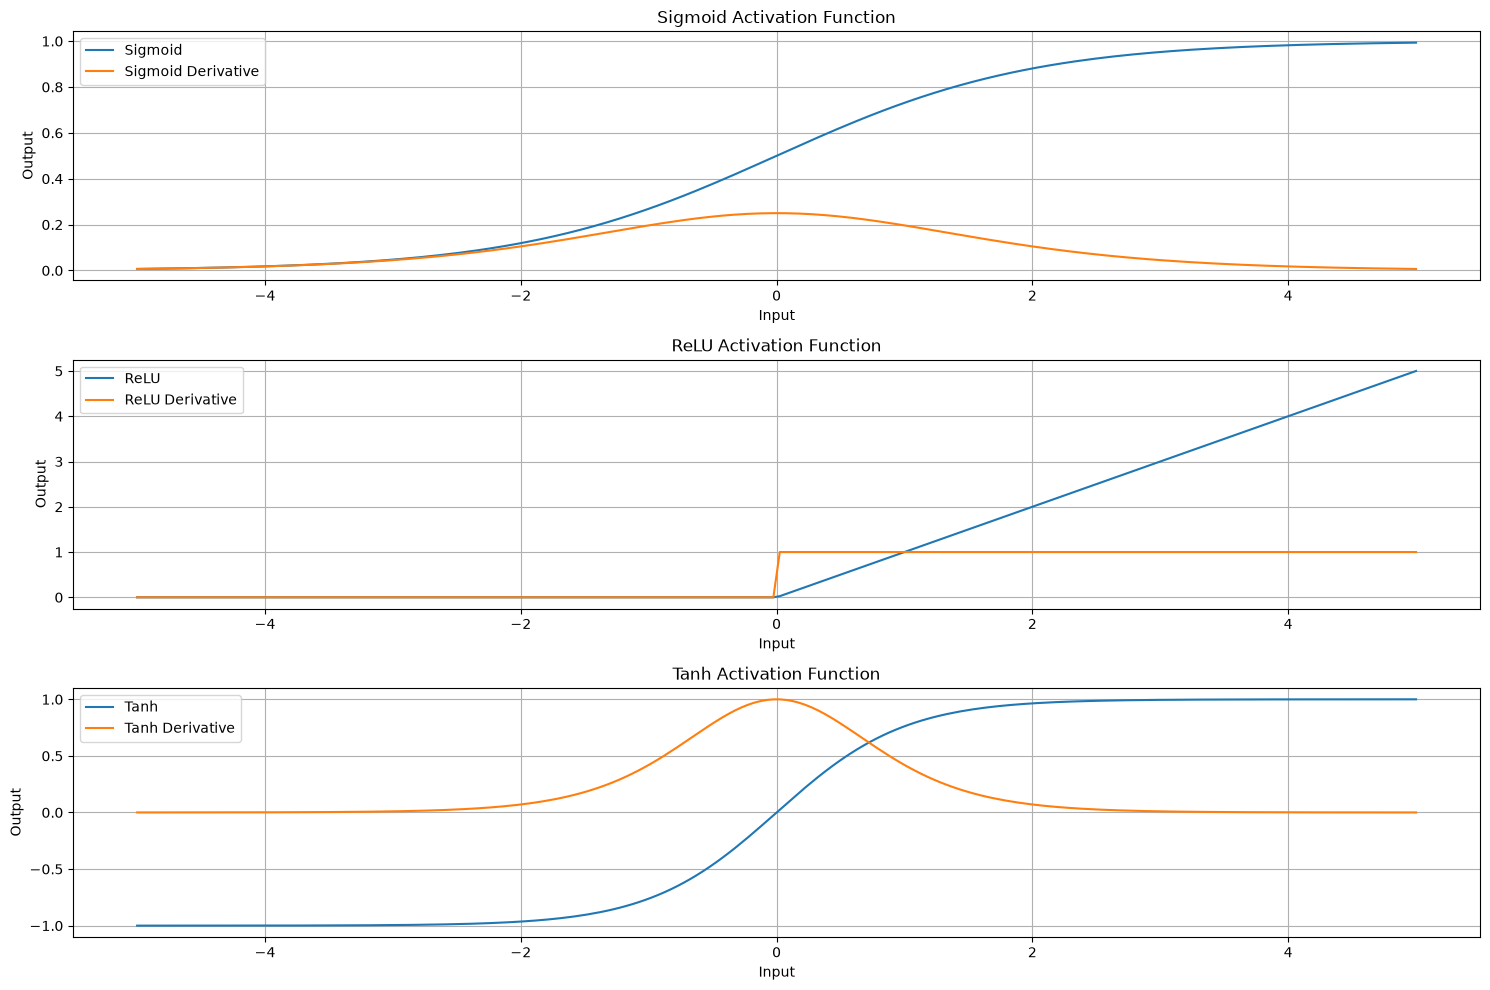

In [4]:
plt.figure(figsize=(15, 10))

plt.subplot(3, 1, 1)
plt.plot(x, sigmoid(x), label="Sigmoid")
plt.plot(x, sigmoid_derivative(x), label="Sigmoid Derivative")
plt.title("Sigmoid Activation Function")
plt.xlabel("Input")
plt.ylabel("Output")
plt.legend()
plt.grid()

plt.subplot(3, 1, 2)
plt.plot(x, relu(x), label="ReLU")
plt.plot(x, relu_derivative(x), label="ReLU Derivative")
plt.title("ReLU Activation Function")
plt.xlabel("Input")
plt.ylabel("Output")
plt.legend()
plt.grid()

plt.subplot(3, 1, 3)
plt.plot(x, tanh(x), label="Tanh")
plt.plot(x, tanh_derivative(x), label="Tanh Derivative")
plt.title("Tanh Activation Function")
plt.xlabel("Input")
plt.ylabel("Output")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [5]:
def single_neuron(inputs, weights, bias, activation):

    z = np.dot(inputs, weights) + bias

    output = activation(z)

    return output

In [6]:
inputs = np.array([0.5, 0.8, 0.2])

weights = np.array([0.4, 0.6, 0.3])

bias = 0.5

output_sigmoid = single_neuron(
    inputs, weights, bias, sigmoid
)    

output_relu = single_neuron(
    inputs, weights, bias, relu
)

output_tanh = single_neuron(
    inputs, weights, bias, tanh
)

print("Sigmoid Output:", output_sigmoid)
print("ReLU Output:", output_relu)
print("Tanh Output:", output_tanh)

Sigmoid Output: 0.7755640142690734
ReLU Output: 1.24
Tanh Output: 0.8454555957266802


In [7]:
z = np.dot(inputs, weights) + bias

print("Input:", inputs)
print("Weights:", weights)
print("Bias:", bias)
print("Weighted Sum (z):", z)

print("\nActivation Outputs")
print("Sigmoid:", sigmoid(z))
print("ReLU:", relu(z))
print("Tanh:", tanh(z))

Input: [0.5 0.8 0.2]
Weights: [0.4 0.6 0.3]
Bias: 0.5
Weighted Sum (z): 1.24

Activation Outputs
Sigmoid: 0.7755640142690734
ReLU: 1.24
Tanh: 0.8454555957266802


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import struct

In [9]:
def load_images(filename):

    with open(filename, 'rb') as file:

        magic, num_images, rows, cols = struct.unpack(
            '>IIII', file.read(16)
        )

        images = np.frombuffer(
            file.read(), dtype=np.uint8
        )

        images = images.reshape(num_images, rows, cols)

    return images

In [10]:
def load_labels(filename):

    with open(filename, 'rb') as file:

        magic, num_labels = struct.unpack(
            '>II', file.read(8)
        )

        labels = np.frombuffer(
            file.read(), dtype=np.uint8
        )

    return labels

In [11]:
X_train = load_images("MNIST/train-images.idx3-ubyte")
y_train = load_labels("MNIST/train-labels.idx1-ubyte")

X_test = load_images("MNIST/t10k-images.idx3-ubyte")
y_test = load_labels("MNIST/t10k-labels.idx1-ubyte")

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


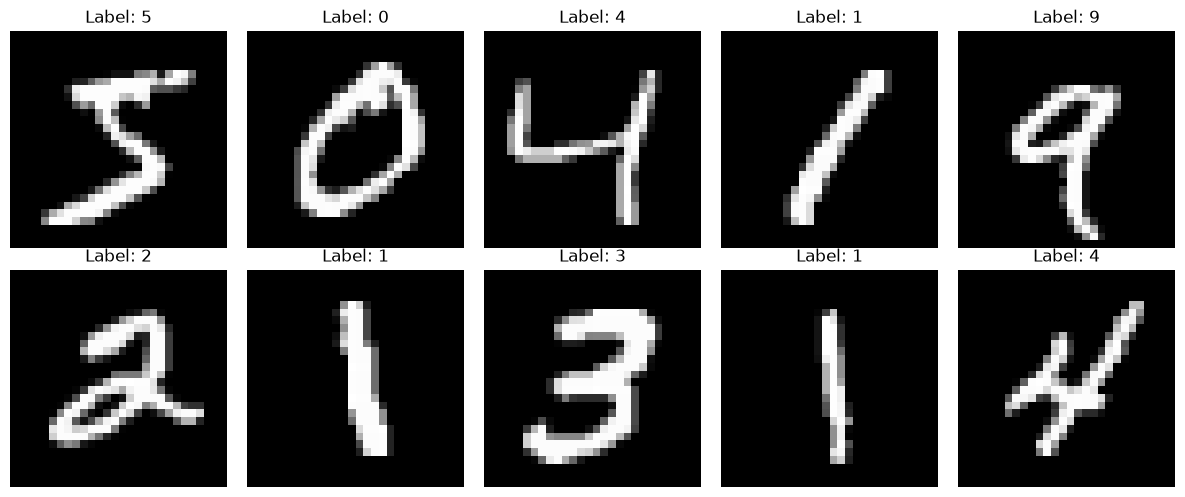

In [12]:
plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i], cmap='gray')

    plt.title(f"Label: {y_train[i]}")

    plt.axis('off')

plt.tight_layout()
plt.show()

Original Image Shape: (28, 28)
Actual Digit: 5


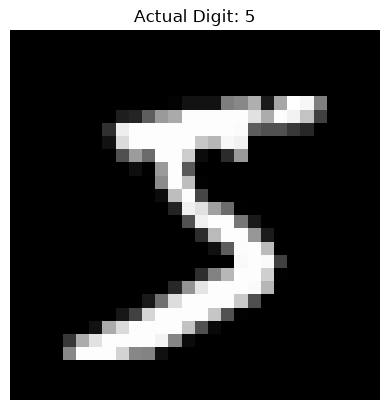

In [13]:
# Select one image
image_index = 0

sample_image = X_train[image_index]
actual_label = y_train[image_index]

print("Original Image Shape:", sample_image.shape)
print("Actual Digit:", actual_label)

# Display the selected image
plt.imshow(sample_image, cmap='gray')
plt.title(f"Actual Digit: {actual_label}")
plt.axis('off')
plt.show()

In [14]:
# Flatten image: 28 x 28 -> 784
X = sample_image.reshape(1, 784)

# Normalize pixel values
X = X.astype(np.float32) / 255.0

print("Input Shape:", X.shape)
print("\nFirst 20 Pixel Values:")
print(X[0, :20])

Input Shape: (1, 784)

First 20 Pixel Values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [15]:
# Set random seed for reproducibility
np.random.seed(42)

# Network architecture
input_size = 784
hidden_size = 64
output_size = 10

# Initialize weights using He initialization
W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)

# Initialize first bias
b1 = np.zeros((1, hidden_size))

# Initialize second layer weights
W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2 / hidden_size)

# Initialize second bias
b2 = np.zeros((1, output_size))

print("Weight and Bias Shapes:")
print("W1:", W1.shape)
print("b1:", b1.shape)
print("W2:", W2.shape)
print("b2:", b2.shape)

print("\nFirst 5 values of W1:")
print(W1[:5, :5])

print("\nFirst 5 values of W2:")
print(W2[:5, :5])

Weight and Bias Shapes:
W1: (784, 64)
b1: (1, 64)
W2: (64, 10)
b2: (1, 10)

First 5 values of W1:
[[ 0.02508785 -0.0069834   0.03271321  0.07692462 -0.01182653]
 [ 0.04103875  0.06850047 -0.00363706  0.05068607  0.01826538]
 [ 0.00503315 -0.02542936 -0.07832033  0.00346295 -0.05365444]
 [ 0.01081337 -0.06291931  0.00874696  0.01946147 -0.04464154]
 [ 0.06398868 -0.03574271  0.02241627  0.03912493 -0.04681706]]

First 5 values of W2:
[[ 0.16517466  0.00385236  0.12614117 -0.14502712 -0.05885225]
 [ 0.2401865   0.20593199  0.28071764 -0.33733822  0.0354831 ]
 [ 0.60137232  0.05606133  0.0634861   0.14517244  0.03193374]
 [ 0.28803867  0.01891564  0.2544588  -0.39454124  0.25782652]
 [-0.07515444 -0.11428874 -0.0638447  -0.26019925 -0.08497838]]


In [16]:
def softmax(x):

    # Numerical stability
    exp_values = np.exp(x - np.max(x, axis=1, keepdims=True))

    probabilities = exp_values / np.sum(
        exp_values, axis=1, keepdims=True
    )

    return probabilities

In [17]:
def forward_propagation(X, W1, b1, W2, b2):

    # Hidden layer
    Z1 = np.dot(X, W1) + b1
    A1 = relu(Z1)

    # Output layer
    Z2 = np.dot(A1, W2) + b2
    A2 = softmax(Z2)

    return Z1, A1, Z2, A2

In [18]:
# Perform forward propagation
Z1, A1, Z2, A2 = forward_propagation(
    X, W1, b1, W2, b2
)

print("========== FORWARD PROPAGATION RESULTS ==========")

print("\n1. Input Layer")
print("Shape:", X.shape)
print("Values (first 20):")
print(X[0, :20])

print("\n2. Hidden Layer - Weighted Sum (Z1)")
print("Shape:", Z1.shape)
print("Values:")
print(Z1)

print("\n3. Hidden Layer - ReLU Output (A1)")
print("Shape:", A1.shape)
print("Values:")
print(A1)

print("\n4. Output Layer - Weighted Sum (Z2)")
print("Shape:", Z2.shape)
print("Values:")
print(Z2)

print("\n5. Output Layer - Softmax Probabilities (A2)")
print("Shape:", A2.shape)
print("Values:")
print(A2)

========== FORWARD PROPAGATION RESULTS ==========

1. Input Layer
Shape: (1, 784)
Values (first 20):
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

2. Hidden Layer - Weighted Sum (Z1)
Shape: (1, 64)
Values:
[[ 3.93146222e-01  4.89084024e-02 -2.31337869e-01  4.77201609e-02
   9.93954946e-01  6.30365892e-02  9.02137975e-01 -2.50904040e-02
   1.18727219e-01 -2.76491711e-01 -5.10014212e-01  2.93539639e-01
  -2.43566758e-01  4.21636233e-01 -4.97846599e-01  2.24867966e-01
  -4.91072691e-01  4.74744402e-01  4.64647059e-01  2.17857837e-02
   7.43200384e-01 -2.47645554e-01 -7.77626186e-01 -4.84818654e-01
  -2.11038488e-02  7.62731573e-01  1.89210545e-01  3.10623347e-01
  -5.97973722e-01 -2.71355071e-01 -2.12931448e-01 -8.47754291e-01
   4.05310560e-01  5.93721297e-01  1.98671339e-01 -5.74864729e-01
  -4.75424999e-02  6.28599259e-01  7.31342931e-02  5.47581549e-02
   1.27668862e-01  6.68674918e-01  3.01737954e-01  4.38709811e-01
   3.61234161e-04 -1.06914031e+00  3.99401501e-01  

In [19]:
# Get predicted digit
predicted_digit = np.argmax(A2)

# Get highest probability
confidence = np.max(A2) * 100

print("Actual Digit:", actual_label)
print("Predicted Digit:", predicted_digit)
print("Prediction Confidence: {:.2f}%".format(confidence))

print("\nSum of Output Probabilities:")
print(np.sum(A2))

print("\nPrediction Status:")
if predicted_digit == actual_label:
    print("Prediction matches the actual digit.")
else:
    print("Prediction does not match the actual digit.")

Actual Digit: 5
Predicted Digit: 1
Prediction Confidence: 22.76%

Sum of Output Probabilities:
1.0

Prediction Status:
Prediction does not match the actual digit.


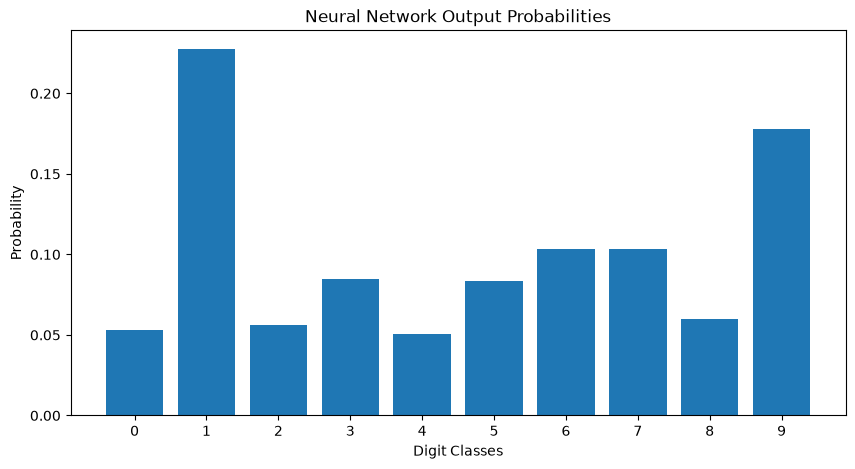

In [20]:
plt.figure(figsize=(10, 5))

plt.bar(range(10), A2[0])

plt.xticks(range(10))

plt.xlabel("Digit Classes")
plt.ylabel("Probability")

plt.title("Neural Network Output Probabilities")

plt.show()

In [21]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader, random_split

In [22]:
print("PyTorch Version:", torch.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training Device:", device)

PyTorch Version: 2.15.0+cpu
Training Device: cpu


In [23]:
# Flatten training and testing images
X_train_flat = X_train.reshape(-1, 784)
X_test_flat = X_test.reshape(-1, 784)

# Normalize pixel values
X_train_flat = X_train_flat.astype(np.float32) / 255.0
X_test_flat = X_test_flat.astype(np.float32) / 255.0

# Convert images into PyTorch tensors
X_train_tensor = torch.tensor(X_train_flat, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_test_tensor = torch.tensor(X_test_flat, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("Training Images:", X_train_tensor.shape)
print("Training Labels:", y_train_tensor.shape)

print("Testing Images:", X_test_tensor.shape)
print("Testing Labels:", y_test_tensor.shape)

Training Images: torch.Size([60000, 784])
Training Labels: torch.Size([60000])
Testing Images: torch.Size([10000, 784])
Testing Labels: torch.Size([10000])


In [24]:
# Combine training images and labels
full_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

# Split dataset
train_dataset, val_dataset = random_split(
    full_dataset,
    [50000, 10000],
    generator=torch.Generator().manual_seed(42)
)

# Batch size
batch_size = 64

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training Samples:", len(train_dataset))
print("Validation Samples:", len(val_dataset))
print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))

Training Samples: 50000
Validation Samples: 10000
Training Batches: 782
Validation Batches: 157


In [25]:
class MNIST_MLP(nn.Module):

    def __init__(self):
        super(MNIST_MLP, self).__init__()

        # First hidden layer: 784 -> 128
        self.fc1 = nn.Linear(784, 128)

        # Second hidden layer: 128 -> 64
        self.fc2 = nn.Linear(128, 64)

        # Output layer: 64 -> 10
        self.fc3 = nn.Linear(64, 10)

        # ReLU activation
        self.relu = nn.ReLU()

    def forward(self, x):

        # First hidden layer
        x = self.relu(self.fc1(x))

        # Second hidden layer
        x = self.relu(self.fc2(x))

        # Output layer
        x = self.fc3(x)

        return x

In [26]:
# Create model
model = MNIST_MLP().to(device)

# Loss function
criterion = nn.CrossEntropyLoss()

# Adam optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Display model architecture
print(model)

MNIST_MLP(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)


In [27]:
# Number of epochs
epochs = 15

# Store metrics
train_accuracies = []
val_accuracies = []

train_losses = []
val_losses = []

for epoch in range(epochs):

    # =========================
    # TRAINING
    # =========================

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Calculate training loss
        running_loss += loss.item() * images.size(0)

        # Calculate predictions
        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_accuracy = 100 * correct / total

    # =========================
    # VALIDATION
    # =========================

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_running_loss / val_total
    epoch_val_accuracy = 100 * val_correct / val_total

    # Store metrics
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    train_accuracies.append(epoch_train_accuracy)
    val_accuracies.append(epoch_val_accuracy)

    # Display results
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Accuracy: {epoch_train_accuracy:.2f}% | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Accuracy: {epoch_val_accuracy:.2f}%"
    )

Epoch [1/15] Train Loss: 0.3681 | Train Accuracy: 89.50% | Val Loss: 0.2123 | Val Accuracy: 93.88%
Epoch [2/15] Train Loss: 0.1540 | Train Accuracy: 95.42% | Val Loss: 0.1573 | Val Accuracy: 95.30%
Epoch [3/15] Train Loss: 0.1076 | Train Accuracy: 96.76% | Val Loss: 0.1323 | Val Accuracy: 96.04%
Epoch [4/15] Train Loss: 0.0817 | Train Accuracy: 97.47% | Val Loss: 0.1131 | Val Accuracy: 96.50%
Epoch [5/15] Train Loss: 0.0637 | Train Accuracy: 98.01% | Val Loss: 0.1062 | Val Accuracy: 96.83%
Epoch [6/15] Train Loss: 0.0524 | Train Accuracy: 98.33% | Val Loss: 0.1035 | Val Accuracy: 97.03%
Epoch [7/15] Train Loss: 0.0412 | Train Accuracy: 98.69% | Val Loss: 0.0987 | Val Accuracy: 97.18%
Epoch [8/15] Train Loss: 0.0329 | Train Accuracy: 98.99% | Val Loss: 0.1012 | Val Accuracy: 97.33%
Epoch [9/15] Train Loss: 0.0258 | Train Accuracy: 99.22% | Val Loss: 0.1029 | Val Accuracy: 97.44%
Epoch [10/15] Train Loss: 0.0256 | Train Accuracy: 99.16% | Val Loss: 0.0975 | Val Accuracy: 97.57%
Epoch [11

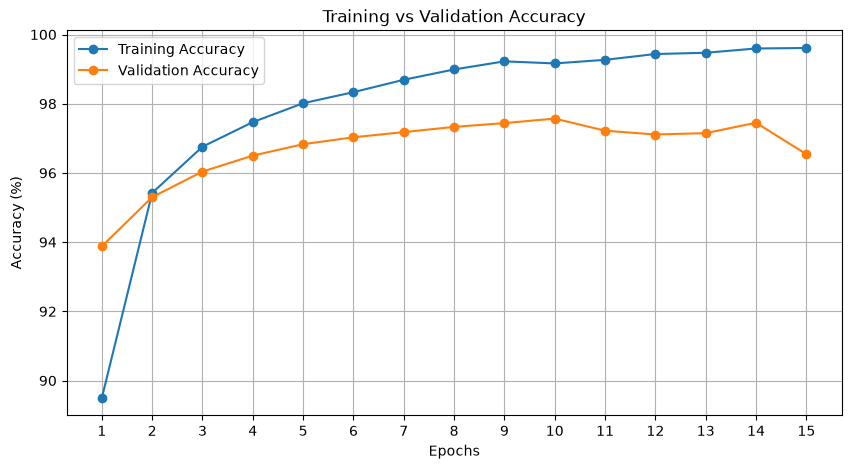

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, epochs + 1),
    train_accuracies,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    range(1, epochs + 1),
    val_accuracies,
    marker='o',
    label='Validation Accuracy'
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")

plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True)

plt.show()

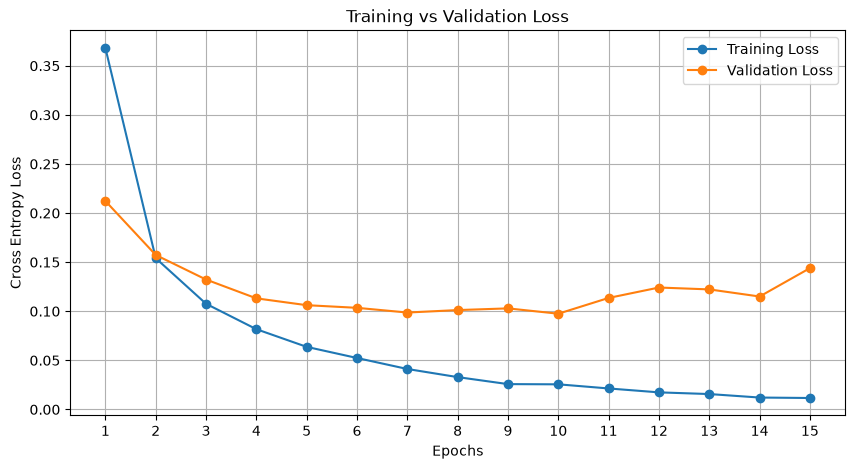

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    marker='o',
    label='Training Loss'
)

plt.plot(
    range(1, epochs + 1),
    val_losses,
    marker='o',
    label='Validation Loss'
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Cross Entropy Loss")

plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True)

plt.show()

In [30]:
print("========== FINAL TRAINING RESULTS ==========")

print(f"Total Epochs: {epochs}")

print(f"Final Training Accuracy: {train_accuracies[-1]:.2f}%")

print(f"Final Validation Accuracy: {val_accuracies[-1]:.2f}%")

print(f"Final Training Loss: {train_losses[-1]:.4f}")

print(f"Final Validation Loss: {val_losses[-1]:.4f}")

========== FINAL TRAINING RESULTS ==========
Total Epochs: 15
Final Training Accuracy: 99.61%
Final Validation Accuracy: 96.54%
Final Training Loss: 0.0116
Final Validation Loss: 0.1439


In [31]:
class Flexible_MLP(nn.Module):

    def __init__(self, hidden_sizes):
        super(Flexible_MLP, self).__init__()

        layers = []

        input_size = 784

        # Create hidden layers
        for hidden_size in hidden_sizes:

            layers.append(
                nn.Linear(input_size, hidden_size)
            )

            layers.append(nn.ReLU())

            input_size = hidden_size

        # Output layer
        layers.append(nn.Linear(input_size, 10))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

In [32]:
def train_model(hidden_sizes, learning_rate, epochs=10):

    # Reproducible initialization
    torch.manual_seed(42)

    # Create model
    model = Flexible_MLP(hidden_sizes).to(device)

    # Loss function
    criterion = nn.CrossEntropyLoss()

    # Adam optimizer
    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    for epoch in range(epochs):

        # =====================
        # TRAINING
        # =====================

        model.train()

        train_correct = 0
        train_total = 0
        train_loss = 0.0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            train_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            train_correct += (predictions == labels).sum().item()

            train_total += labels.size(0)

        train_accuracy = 100 * train_correct / train_total

        # =====================
        # VALIDATION
        # =====================

        model.eval()

        val_correct = 0
        val_total = 0
        val_loss = 0.0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)

                predictions = torch.argmax(outputs, dim=1)

                val_correct += (predictions == labels).sum().item()

                val_total += labels.size(0)

        val_accuracy = 100 * val_correct / val_total

        # Display progress
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Accuracy: {train_accuracy:.2f}% | "
            f"Validation Accuracy: {val_accuracy:.2f}%"
        )

    # Return final results
    return {
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "val_loss": val_loss / val_total,
        "model": model
    }

In [33]:
learning_rates = [0.001, 0.01, 0.1]

learning_rate_results = []

for lr in learning_rates:

    print("\n" + "=" * 50)
    print("Learning Rate:", lr)
    print("=" * 50)

    result = train_model(
        hidden_sizes=[128, 64],
        learning_rate=lr,
        epochs=10
    )

    learning_rate_results.append({
        "Experiment": "Learning Rate",
        "Configuration": str(lr),
        "Train Accuracy": result["train_accuracy"],
        "Validation Accuracy": result["val_accuracy"],
        "Validation Loss": result["val_loss"]
    })


Learning Rate: 0.001
Epoch [1/10] Train Accuracy: 89.61% | Validation Accuracy: 93.60%
Epoch [2/10] Train Accuracy: 95.34% | Validation Accuracy: 95.63%
Epoch [3/10] Train Accuracy: 96.72% | Validation Accuracy: 96.34%
Epoch [4/10] Train Accuracy: 97.49% | Validation Accuracy: 96.82%
Epoch [5/10] Train Accuracy: 98.12% | Validation Accuracy: 96.66%
Epoch [6/10] Train Accuracy: 98.37% | Validation Accuracy: 97.11%
Epoch [7/10] Train Accuracy: 98.73% | Validation Accuracy: 97.28%
Epoch [8/10] Train Accuracy: 98.94% | Validation Accuracy: 96.83%
Epoch [9/10] Train Accuracy: 99.16% | Validation Accuracy: 97.09%
Epoch [10/10] Train Accuracy: 99.14% | Validation Accuracy: 97.24%

Learning Rate: 0.01
Epoch [1/10] Train Accuracy: 92.32% | Validation Accuracy: 95.26%
Epoch [2/10] Train Accuracy: 95.87% | Validation Accuracy: 95.77%
Epoch [3/10] Train Accuracy: 96.40% | Validation Accuracy: 94.45%
Epoch [4/10] Train Accuracy: 96.84% | Validation Accuracy: 96.18%
Epoch [5/10] Train Accuracy: 97.

In [34]:
hidden_sizes_list = [32, 64, 128, 256]

hidden_size_results = []

for size in hidden_sizes_list:

    print("\n" + "=" * 50)
    print("Hidden Layer Size:", size)
    print("=" * 50)

    result = train_model(
        hidden_sizes=[size, size],
        learning_rate=0.001,
        epochs=10
    )

    hidden_size_results.append({
        "Experiment": "Hidden Layer Size",
        "Configuration": str(size),
        "Train Accuracy": result["train_accuracy"],
        "Validation Accuracy": result["val_accuracy"],
        "Validation Loss": result["val_loss"]
    })


Hidden Layer Size: 32
Epoch [1/10] Train Accuracy: 86.88% | Validation Accuracy: 92.24%
Epoch [2/10] Train Accuracy: 93.33% | Validation Accuracy: 93.58%
Epoch [3/10] Train Accuracy: 94.67% | Validation Accuracy: 94.50%
Epoch [4/10] Train Accuracy: 95.46% | Validation Accuracy: 94.80%
Epoch [5/10] Train Accuracy: 96.03% | Validation Accuracy: 95.08%
Epoch [6/10] Train Accuracy: 96.42% | Validation Accuracy: 95.38%
Epoch [7/10] Train Accuracy: 96.72% | Validation Accuracy: 95.41%
Epoch [8/10] Train Accuracy: 96.99% | Validation Accuracy: 95.44%
Epoch [9/10] Train Accuracy: 97.29% | Validation Accuracy: 95.79%
Epoch [10/10] Train Accuracy: 97.44% | Validation Accuracy: 95.80%

Hidden Layer Size: 64
Epoch [1/10] Train Accuracy: 88.70% | Validation Accuracy: 92.60%
Epoch [2/10] Train Accuracy: 94.58% | Validation Accuracy: 94.96%
Epoch [3/10] Train Accuracy: 96.04% | Validation Accuracy: 95.42%
Epoch [4/10] Train Accuracy: 96.94% | Validation Accuracy: 96.36%
Epoch [5/10] Train Accuracy: 

In [35]:
architectures = {
    "1 Hidden Layer": [128],
    "2 Hidden Layers": [128, 64],
    "3 Hidden Layers": [128, 64, 32]
}

layer_results = []

for name, hidden_sizes in architectures.items():

    print("\n" + "=" * 50)
    print("Architecture:", name)
    print("Hidden Layers:", hidden_sizes)
    print("=" * 50)

    result = train_model(
        hidden_sizes=hidden_sizes,
        learning_rate=0.001,
        epochs=10
    )

    layer_results.append({
        "Experiment": "Number of Hidden Layers",
        "Configuration": name,
        "Train Accuracy": result["train_accuracy"],
        "Validation Accuracy": result["val_accuracy"],
        "Validation Loss": result["val_loss"]
    })


Architecture: 1 Hidden Layer
Hidden Layers: [128]
Epoch [1/10] Train Accuracy: 89.90% | Validation Accuracy: 93.63%
Epoch [2/10] Train Accuracy: 95.11% | Validation Accuracy: 95.27%
Epoch [3/10] Train Accuracy: 96.58% | Validation Accuracy: 95.98%
Epoch [4/10] Train Accuracy: 97.40% | Validation Accuracy: 96.43%
Epoch [5/10] Train Accuracy: 97.93% | Validation Accuracy: 96.85%
Epoch [6/10] Train Accuracy: 98.27% | Validation Accuracy: 97.07%
Epoch [7/10] Train Accuracy: 98.71% | Validation Accuracy: 97.05%
Epoch [8/10] Train Accuracy: 98.93% | Validation Accuracy: 97.16%
Epoch [9/10] Train Accuracy: 99.13% | Validation Accuracy: 96.98%
Epoch [10/10] Train Accuracy: 99.31% | Validation Accuracy: 97.27%

Architecture: 2 Hidden Layers
Hidden Layers: [128, 64]
Epoch [1/10] Train Accuracy: 89.61% | Validation Accuracy: 93.60%
Epoch [2/10] Train Accuracy: 95.34% | Validation Accuracy: 95.63%
Epoch [3/10] Train Accuracy: 96.72% | Validation Accuracy: 96.34%
Epoch [4/10] Train Accuracy: 97.49

In [36]:
import pandas as pd

# Combine all experiment results
all_results = (
    learning_rate_results
    + hidden_size_results
    + layer_results
)

# Create summary DataFrame
results_df = pd.DataFrame(all_results)

# Sort by validation accuracy
results_df = results_df.sort_values(
    by="Validation Accuracy",
    ascending=False
).reset_index(drop=True)

# Display results
print("========== HYPERPARAMETER EXPERIMENT RESULTS ==========")

display(
    results_df.round(2)
)

========== HYPERPARAMETER EXPERIMENT RESULTS ==========


,Experiment,Configuration,Train Accuracy,Validation Accuracy,Validation Loss
0,Hidden Layer Size,256,99.39,97.33,0.11
1,Hidden Layer Size,128,99.24,97.32,0.11
2,Number of Hidden Layers,1 Hidden Layer,99.31,97.27,0.09
3,Learning Rate,0.001,99.14,97.24,0.11
4,Number of Hidden Layers,2 Hidden Layers,99.14,97.24,0.11
5,Hidden Layer Size,64,98.92,97.00,0.11
6,Number of Hidden Layers,3 Hidden Layers,99.10,96.75,0.12
7,Learning Rate,0.01,97.80,96.05,0.22
8,Hidden Layer Size,32,97.44,95.80,0.14
9,Learning Rate,0.1,19.15,21.17,2.00


In [37]:
best_results = results_df.loc[
    results_df.groupby("Experiment")["Validation Accuracy"].idxmax()
]

print("========== BEST CONFIGURATION PER EXPERIMENT ==========")

display(
    best_results[
        [
            "Experiment",
            "Configuration",
            "Validation Accuracy",
            "Validation Loss"
        ]
    ].reset_index(drop=True).round(2)
)

========== BEST CONFIGURATION PER EXPERIMENT ==========


,Experiment,Configuration,Validation Accuracy,Validation Loss
0,Hidden Layer Size,256,97.33,0.11
1,Learning Rate,0.001,97.24,0.11
2,Number of Hidden Layers,1 Hidden Layer,97.27,0.09


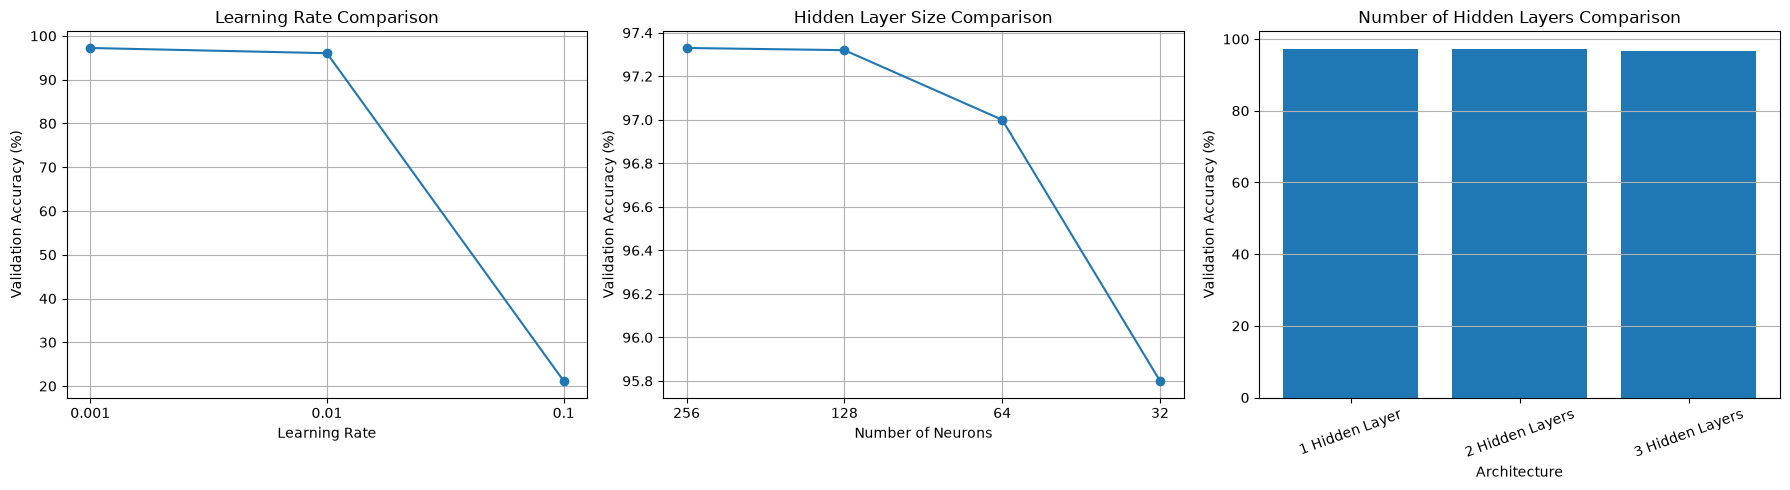

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Learning rate comparison
lr_df = results_df[
    results_df["Experiment"] == "Learning Rate"
]

axes[0].plot(
    lr_df["Configuration"],
    lr_df["Validation Accuracy"],
    marker='o'
)

axes[0].set_title("Learning Rate Comparison")
axes[0].set_xlabel("Learning Rate")
axes[0].set_ylabel("Validation Accuracy (%)")
axes[0].grid(True)


# Hidden size comparison
size_df = results_df[
    results_df["Experiment"] == "Hidden Layer Size"
]

axes[1].plot(
    size_df["Configuration"],
    size_df["Validation Accuracy"],
    marker='o'
)

axes[1].set_title("Hidden Layer Size Comparison")
axes[1].set_xlabel("Number of Neurons")
axes[1].set_ylabel("Validation Accuracy (%)")
axes[1].grid(True)


# Number of hidden layers comparison
depth_df = results_df[
    results_df["Experiment"] == "Number of Hidden Layers"
]

axes[2].bar(
    depth_df["Configuration"],
    depth_df["Validation Accuracy"]
)

axes[2].set_title("Number of Hidden Layers Comparison")
axes[2].set_xlabel("Architecture")
axes[2].set_ylabel("Validation Accuracy (%)")
axes[2].tick_params(axis='x', rotation=20)
axes[2].grid(axis='y')

plt.tight_layout()
plt.show()

In [39]:
results_df.to_csv(
    "mnist_hyperparameter_results.csv",
    index=False
)

print("Hyperparameter results saved successfully!")

Hyperparameter results saved successfully!


In [40]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [41]:
class Activation_MLP(nn.Module):
    def __init__(self, activation_name):
        super(Activation_MLP, self).__init__()

        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

        if activation_name == "Sigmoid":
            self.activation = nn.Sigmoid()
        elif activation_name == "ReLU":
            self.activation = nn.ReLU()
        elif activation_name == "Tanh":
            self.activation = nn.Tanh()
        else:
            raise ValueError("Unknown activation function")

        # Use the same initialization approach for all three models
        nn.init.xavier_uniform_(self.fc1.weight)
        nn.init.xavier_uniform_(self.fc2.weight)
        nn.init.xavier_uniform_(self.fc3.weight)

    def forward(self, x):
        x = self.activation(self.fc1(x))
        x = self.activation(self.fc2(x))
        x = self.fc3(x)

        return x

In [42]:
def train_activation_model(activation_name, epochs=15):

    torch.manual_seed(42)

    model = Activation_MLP(activation_name).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    history = {
        "train_accuracy": [],
        "val_accuracy": [],
        "train_loss": [],
        "val_loss": [],
        "epoch_times": []
    }

    start_time = time.time()
    time_to_90 = None

    for epoch in range(epochs):

        epoch_start = time.time()

        # Training
        model.train()

        train_correct = 0
        train_total = 0
        train_loss = 0.0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            train_correct += (predictions == labels).sum().item()
            train_total += labels.size(0)

        train_accuracy = 100 * train_correct / train_total
        train_loss = train_loss / train_total

        # Validation
        model.eval()

        val_correct = 0
        val_total = 0
        val_loss = 0.0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)

                predictions = torch.argmax(outputs, dim=1)

                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        val_accuracy = 100 * val_correct / val_total
        val_loss = val_loss / val_total

        epoch_time = time.time() - epoch_start
        elapsed_time = time.time() - start_time

        # Save metrics
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["epoch_times"].append(epoch_time)

        # Record first time validation accuracy reaches 90%
        if val_accuracy >= 90 and time_to_90 is None:
            time_to_90 = elapsed_time

        print(
            f"{activation_name} | "
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train: {train_accuracy:.2f}% | "
            f"Validation: {val_accuracy:.2f}%"
        )

    total_training_time = time.time() - start_time

    # Final evaluation on the official test set
    model.eval()

    test_correct = 0
    test_total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            test_correct += (predictions == labels).sum().item()
            test_total += labels.size(0)

    test_accuracy = 100 * test_correct / test_total

    return {
        "model": model,
        "history": history,
        "train_accuracy": history["train_accuracy"][-1],
        "val_accuracy": history["val_accuracy"][-1],
        "test_accuracy": test_accuracy,
        "time_to_90": time_to_90,
        "total_training_time": total_training_time
    }

In [44]:
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [45]:
activation_names = ["Sigmoid", "ReLU", "Tanh"]

activation_results = {}
activation_models = {}

for activation_name in activation_names:

    print("\n" + "=" * 50)
    print("Training:", activation_name)
    print("=" * 50)

    result = train_activation_model(
        activation_name=activation_name,
        epochs=15
    )

    activation_results[activation_name] = result
    activation_models[activation_name] = result["model"]

    print(f"\n{activation_name} Results:")
    print(f"Final Validation Accuracy: {result['val_accuracy']:.2f}%")
    print(f"Final Test Accuracy: {result['test_accuracy']:.2f}%")
    print(f"Total Training Time: {result['total_training_time']:.2f} seconds")

    if result["time_to_90"] is not None:
        print(f"Time to 90% Validation Accuracy: {result['time_to_90']:.2f} seconds")
    else:
        print("90% Validation Accuracy: Not reached")


Training: Sigmoid
Sigmoid | Epoch 1/15 | Train: 84.28% | Validation: 91.62%
Sigmoid | Epoch 2/15 | Train: 93.27% | Validation: 93.64%
Sigmoid | Epoch 3/15 | Train: 95.03% | Validation: 94.67%
Sigmoid | Epoch 4/15 | Train: 96.11% | Validation: 95.54%
Sigmoid | Epoch 5/15 | Train: 96.93% | Validation: 95.73%
Sigmoid | Epoch 6/15 | Train: 97.51% | Validation: 96.32%
Sigmoid | Epoch 7/15 | Train: 97.93% | Validation: 96.76%
Sigmoid | Epoch 8/15 | Train: 98.23% | Validation: 96.66%
Sigmoid | Epoch 9/15 | Train: 98.56% | Validation: 97.07%
Sigmoid | Epoch 10/15 | Train: 98.80% | Validation: 97.22%
Sigmoid | Epoch 11/15 | Train: 99.09% | Validation: 97.28%
Sigmoid | Epoch 12/15 | Train: 99.27% | Validation: 97.33%
Sigmoid | Epoch 13/15 | Train: 99.42% | Validation: 97.21%
Sigmoid | Epoch 14/15 | Train: 99.50% | Validation: 97.24%
Sigmoid | Epoch 15/15 | Train: 99.61% | Validation: 97.39%

Sigmoid Results:
Final Validation Accuracy: 97.39%
Final Test Accuracy: 97.66%
Total Training Time: 35.0

In [46]:
activation_comparison = []

for name, result in activation_results.items():

    activation_comparison.append({
        "Activation": name,
        "Final Train Accuracy (%)": result["train_accuracy"],
        "Final Validation Accuracy (%)": result["val_accuracy"],
        "Final Test Accuracy (%)": result["test_accuracy"],
        "Time to 90% (seconds)": result["time_to_90"],
        "Total Training Time (seconds)": result["total_training_time"]
    })

activation_df = pd.DataFrame(activation_comparison)

display(activation_df.round(2))

,Activation,Final Train Accuracy (%),Final Validation Accuracy (%),Final Test Accuracy (%),Time to 90% (seconds),Total Training Time (seconds)
0,Sigmoid,99.61,97.39,97.66,2.49,35.01
1,ReLU,99.57,97.64,97.76,2.37,34.43
2,Tanh,99.76,97.06,97.45,2.38,34.64


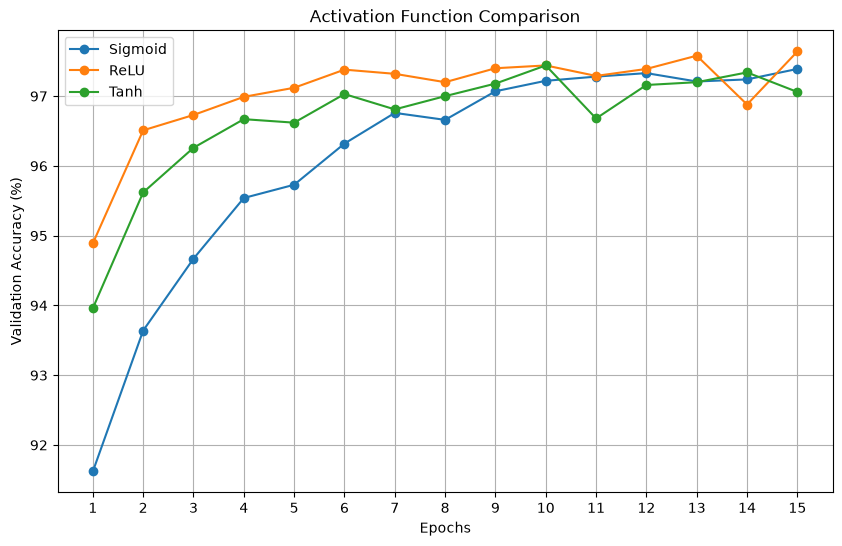

In [47]:
plt.figure(figsize=(10, 6))

for name, result in activation_results.items():

    plt.plot(
        range(1, 16),
        result["history"]["val_accuracy"],
        marker="o",
        label=name
    )

plt.title("Activation Function Comparison")
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy (%)")

plt.xticks(range(1, 16))
plt.legend()
plt.grid(True)

plt.show()

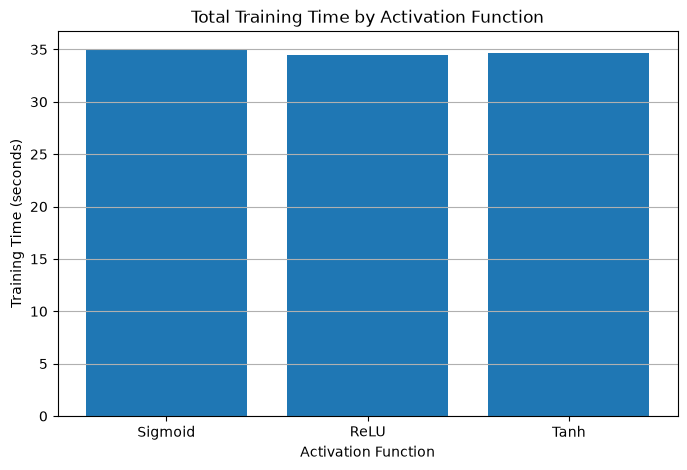

In [48]:
plt.figure(figsize=(8, 5))

plt.bar(
    activation_df["Activation"],
    activation_df["Total Training Time (seconds)"]
)

plt.title("Total Training Time by Activation Function")
plt.xlabel("Activation Function")
plt.ylabel("Training Time (seconds)")

plt.grid(axis="y")
plt.show()

In [49]:
best_activation_name = max(
    activation_results,
    key=lambda name: activation_results[name]["val_accuracy"]
)

best_model = activation_models[best_activation_name]

print("Best activation function:", best_activation_name)
print(
    "Validation Accuracy:",
    round(activation_results[best_activation_name]["val_accuracy"], 2),
    "%"
)

Best activation function: ReLU
Validation Accuracy: 97.64 %


In [50]:
best_model.eval()

all_predictions = []
all_actual_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = best_model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_actual_labels.extend(labels.numpy())

y_pred = np.array(all_predictions)
y_true = np.array(all_actual_labels)

print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)

print("Test Accuracy:", round(np.mean(y_true == y_pred) * 100, 2), "%")

Actual labels shape: (10000,)
Predicted labels shape: (10000,)
Test Accuracy: 97.76 %


<Figure size 1000x800 with 0 Axes>

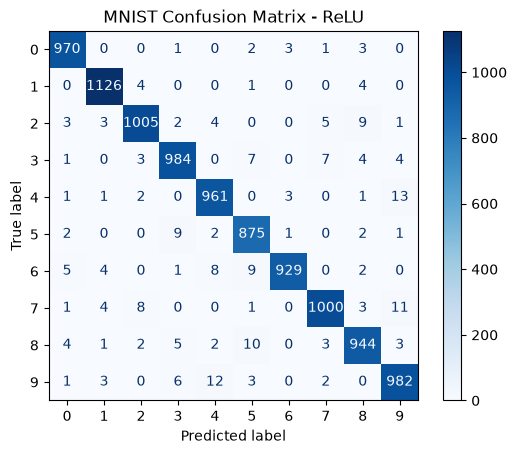

In [51]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(10)
)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title(f"MNIST Confusion Matrix - {best_activation_name}")
plt.show()

In [52]:
confused_pairs = []

for digit1 in range(10):

    for digit2 in range(digit1 + 1, 10):

        confusion_count = cm[digit1, digit2] + cm[digit2, digit1]

        confused_pairs.append({
            "Digit Pair": f"{digit1} <-> {digit2}",
            "Confusion Count": confusion_count,
            f"{digit1} predicted as {digit2}": cm[digit1, digit2],
            f"{digit2} predicted as {digit1}": cm[digit2, digit1]
        })

confused_pairs_df = pd.DataFrame(confused_pairs)

top_3_confused_pairs = confused_pairs_df.sort_values(
    by="Confusion Count",
    ascending=False
).head(3)

display(top_3_confused_pairs)

,Digit Pair,Confusion Count,0 predicted as 1,1 predicted as 0,0 predicted as 2,2 predicted as 0,0 predicted as 3,3 predicted as 0,0 predicted as 4,4 predicted as 0,...,6 predicted as 8,8 predicted as 6,6 predicted as 9,9 predicted as 6,7 predicted as 8,8 predicted as 7,7 predicted as 9,9 predicted as 7,8 predicted as 9,9 predicted as 8
34,4 <-> 9,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25,3 <-> 5,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43,7 <-> 9,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,11.0,2.0,NaN,NaN


Total misclassified images: 224


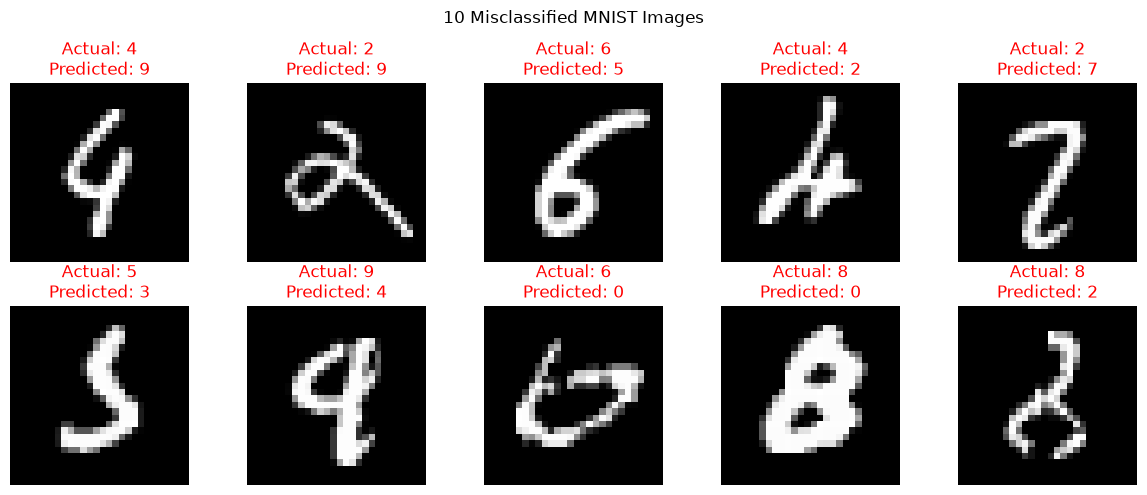

In [53]:
misclassified_indices = np.where(y_true != y_pred)[0]

print("Total misclassified images:", len(misclassified_indices))

num_images = min(10, len(misclassified_indices))

plt.figure(figsize=(12, 5))

for i in range(num_images):

    index = misclassified_indices[i]

    image = X_test[index]

    actual = y_true[index]
    predicted = y_pred[index]

    plt.subplot(2, 5, i + 1)

    plt.imshow(image, cmap="gray")
    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color="red"
    )

    plt.axis("off")

plt.suptitle("10 Misclassified MNIST Images")
plt.tight_layout()
plt.show()

In [54]:
per_digit_accuracy = []

for digit in range(10):

    total = np.sum(y_true == digit)
    correct = cm[digit, digit]

    accuracy = (correct / total) * 100 if total > 0 else 0

    per_digit_accuracy.append({
        "Digit": digit,
        "Correct Predictions": correct,
        "Total Images": total,
        "Accuracy (%)": accuracy
    })

digit_accuracy_df = pd.DataFrame(per_digit_accuracy)

display(digit_accuracy_df.round(2))

,Digit,Correct Predictions,Total Images,Accuracy (%)
0,0,970,980,98.98
1,1,1126,1135,99.21
2,2,1005,1032,97.38
3,3,984,1010,97.43
4,4,961,982,97.86
5,5,875,892,98.09
6,6,929,958,96.97
7,7,1000,1028,97.28
8,8,944,974,96.92
9,9,982,1009,97.32


In [55]:
easiest_digit = digit_accuracy_df.loc[
    digit_accuracy_df["Accuracy (%)"].idxmax()
]

hardest_digit = digit_accuracy_df.loc[
    digit_accuracy_df["Accuracy (%)"].idxmin()
]

print("Easiest Digit:")
print(
    f"Digit {int(easiest_digit['Digit'])} "
    f"with {easiest_digit['Accuracy (%)']:.2f}% accuracy"
)

print("\nHardest Digit:")
print(
    f"Digit {int(hardest_digit['Digit'])} "
    f"with {hardest_digit['Accuracy (%)']:.2f}% accuracy"
)

Easiest Digit:
Digit 1 with 99.21% accuracy

Hardest Digit:
Digit 8 with 96.92% accuracy


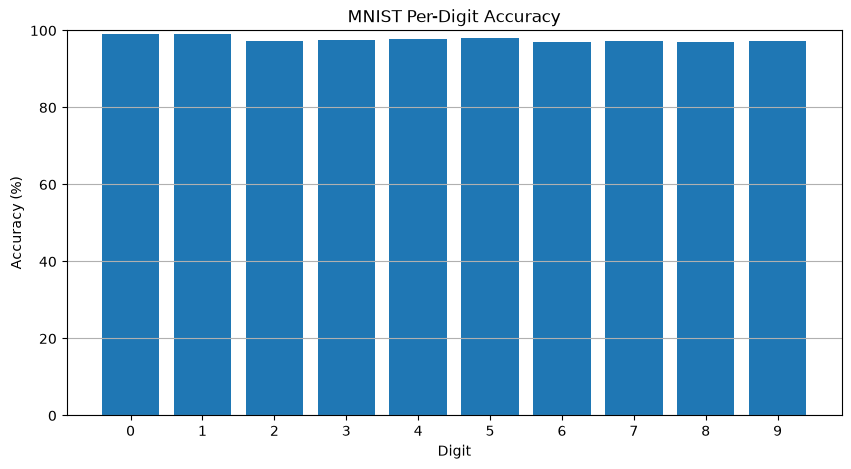

In [56]:
plt.figure(figsize=(10, 5))

plt.bar(
    digit_accuracy_df["Digit"].astype(str),
    digit_accuracy_df["Accuracy (%)"]
)

plt.title("MNIST Per-Digit Accuracy")
plt.xlabel("Digit")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)
plt.grid(axis="y")

plt.show()

In [57]:
activation_df.to_csv(
    "mnist_activation_comparison.csv",
    index=False
)

top_3_confused_pairs.to_csv(
    "mnist_top_confused_pairs.csv",
    index=False
)

digit_accuracy_df.to_csv(
    "mnist_per_digit_accuracy.csv",
    index=False
)

print("Part C results saved successfully!")

Part C results saved successfully!
